In [1]:
from pydantic_settings.sources.providers import dotenv


def my_reducer(left: list[str], right: list[str]) -> list[str]:
    return left + right


left = ["start", "node_1运行完毕"]  #`left`：当前已累计的状态值；  right：本次待合并的新值。

right = ["node_2运行完毕", "node_3运行完毕"]
print(my_reducer(left, right))
#Annotated 的第一个参数是被注解的原始类型，后续参数是附加的元数据。至于这些元数据表示什么、如何解析，则由使用它的框架或工具自行决定。

['start', 'node_1运行完毕', 'node_2运行完毕', 'node_3运行完毕']


In [2]:
#add_messages 的作用可以概括为：在保留历史消息的基础上追加新消息，并允许通过相同的消息 id 覆盖已有消息。
#只要id相同，就会覆盖已有消息。不管是前面的是系统消息、用户消息还是助手消息，后面的消息都会覆盖前面的消息。
from langgraph.graph.message import add_messages
from langchain.messages import HumanMessage, AIMessage, SystemMessage

left = [
    SystemMessage(content="你是个善解人意的助手", id='1'),
    HumanMessage(content="你好", id='2'),
    AIMessage(content="你好~", id='3'),
]

right = [
    HumanMessage(content="我是老王，你是小王", id='2'),
    AIMessage(content="好的，我记住啦", id='3'),
    HumanMessage(content="你是谁？", id='4'),
    AIMessage(content="我是小王", id='5'),
]

merged = add_messages(left, right)

for msg in merged:
    print(msg)

content='你是个善解人意的助手' additional_kwargs={} response_metadata={} id='1'
content='我是老王，你是小王' additional_kwargs={} response_metadata={} id='2'
content='好的，我记住啦' additional_kwargs={} response_metadata={} id='3' tool_calls=[] invalid_tool_calls=[]
content='你是谁？' additional_kwargs={} response_metadata={} id='4'
content='我是小王' additional_kwargs={} response_metadata={} id='5' tool_calls=[] invalid_tool_calls=[]


In [ ]:
#如果某个 State 字段没有显式定义 `Reducer`，LangGraph 会使用默认的状态更新行为：后一次更新值会覆盖该字段原有的状态值。
#换句话说，当节点返回的更新结果中包含某个字段时，如果该字段没有配置 Reducer，LangGraph 不会对新旧值进行追加、合并或累加，
# 而是直接使用本次返回的新值替换原来旧值
from langgraph.graph import StateGraph, START, END
from typing import TypedDict


class OverAllState(TypedDict):
    logs: list[str]
    id: str


def node_a(state: OverAllState):
    return {
        "logs": ["node_a"],
        "id": "node_a"
    }


def node_b(state: OverAllState):
    return {
        "logs": ["node_b"],
        "id": "node_b"
    }


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()
result = graph.invoke({"logs": ["START"], "id": "start"})
print('=' * 30, '-> result <-', '=' * 30)
print(result)

In [1]:
#state 表示当前节点执行时可以访问到的全局状态快照。节点可以通过读取 state 中的字段获取上游节点写入的数据，并基于这些数据完成当前节点的业务逻辑。
#节点本质上是一个可调用对象，通常定义为普通 Python 函数。节点函数被执行时，LangGraph 会自动将当前图运行到该节点时的 State 传入节点函数。
from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from operator import add


class OverAllState(TypedDict):
    logs: Annotated[list[str], add]
    id: str


def node_a(state: OverAllState):
    for k, v in state.items():
        print(f"k: {k}, v: {v}")


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile()
result = graph.invoke({"logs": ["START"], "id": "start"})

k: logs, v: ['START']
k: id, v: start


In [4]:
#在 LangGraph 中，节点函数通常不需要返回更新后的完整状态，只需要返回本节点对状态的局部更新。
#也就是说，节点的返回值可以只包含需要修改的状态字段。
#对于节点没有返回的字段，LangGraph 会保留其原有状态值；
#对于节点返回的字段，LangGraph 会根据该字段是否配置了 Reducer 来决定如何合并更新值。
# 如果字段配置了 Reducer，则使用对应的 Reducer 函数将旧值和新值合并；
# 如果字段没有配置 Reducer，则按照默认规则使用节点返回的新值覆盖原值。
#LangGraph运行时会按照状态字段的Reducer函数将其与当前的最新状态合并。

from langgraph.graph import StateGraph, START, END
from typing import TypedDict, Annotated
from operator import add


class OverAllState(TypedDict):
    logs: Annotated[list[str], add]
    id: str


def node_a(state: OverAllState):
    for k, v in state.items():
        print(f"k: {k}, v: {v}")
    return {
        "logs": ["node_a 更新状态"],  #配置Reducer函数为add，将新值追加到旧值上。
        #"id": "node_a"    #返回的字段id将覆盖原有状态中的id。
    }


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", END)

graph = builder.compile()
result = graph.invoke({"logs": ["START"], "id": "start"})
print('=' * 30, '-> result <-', '=' * 30)
print(result)

k: logs, v: ['START']
k: id, v: start
============================== -> result <- ==============================
{'logs': ['START', 'node_a 更新状态'], 'id': 'start'}


In [5]:
#在某些场景下，我们可能并不希望继续执行 Reducer 的聚合逻辑，而是希望本次更新直接覆盖旧值。这时可以使用 Overwrite。
#   Overwrite 的作用是：告诉 LangGraph 本次状态更新不走该字段原本定义的 Reducer，而是直接用新值覆盖状态中的旧值。
#需要注意的是，Overwrite 只影响当前这一次更新，并不会修改状态字段本身的 Reducer 定义。后续节点如果继续正常返回该字段的更新值，仍然会按照原来的 Reducer 逻辑进行合并。
from langgraph.graph import StateGraph, START, END
from langgraph.types import Overwrite
from typing import TypedDict, Annotated
from operator import add


class OverAllState(TypedDict):
    logs: Annotated[list[str], add]
    id: str


def node_a(state: OverAllState):
    return {
        "logs": ["node_a"],
        "id": "node_a"
    }


def node_b(state: OverAllState):
    return {
        "logs": Overwrite(["node_b"]),
        "id": "node_b"
    }


def node_c(state: OverAllState):
    return {
        "logs": ["node_c"],
        "id": "node_c"
    }


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", "node_c")
builder.add_edge("node_c", END)

graph = builder.compile()
result = graph.invoke({"logs": ["START"], "id": "start"})
print('=' * 30, '-> result <-', '=' * 30)
print(result)  # """id没有写规约函数，只会覆盖原值。"""

============================== -> result <- ==============================
{'logs': ['node_b', 'node_c'], 'id': 'node_c'}


In [9]:
#

from time import sleep
from typing import TypedDict, Annotated
from operator import add
from langgraph.graph import StateGraph, START, END
from langgraph.types import Overwrite


# 1. 定义状态
class OverAllState(TypedDict):
    # 归约的方式是add追加合并
    logs: Annotated[list[str], add]
    """ 如果出现并行节点 同时更新状态 往下游节点传递的时候 必须要有Reducer函数 """
    cur_id: Annotated[str, add]


# 2. 定义节点
def node_1(state: OverAllState) -> OverAllState:
    for k, v in state.items():
        print(f"1k:{k} v:{v}")
    return {
        "logs": ["node_1 运行完毕"]
    }


def node_2(state: OverAllState) -> OverAllState:
    for k, v in state.items():
        print(f"2k:{k} v:{v}")
    return {
        "logs": ["node_2 运行完毕"],
        "cur_id": "node2"
    }


def node_3(state: OverAllState) -> OverAllState:
    sleep(1)
    for k, v in state.items():
        print(f"3k:{k} v:{v}")
    return {
        "logs": ["node_3 运行完毕"],
        "cur_id": "node3"
    }


def node_4(state: OverAllState) -> OverAllState:
    sleep(2)
    for k, v in state.items():
        print(f"4k:{k} v:{v}")
    return {
        "logs": ["node_4 运行完毕"]
    }


builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_node("node_3", node_3)
builder.add_node("node_4", node_4)
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_1", "node_3")
builder.add_edge("node_2", "node_4")
builder.add_edge("node_3", "node_4")
builder.add_edge("node_4", END)

graph = builder.compile()

result = graph.invoke({"logs": ["START"], "cur_id": "start"})
print('=' * 30, '-> result <-', '=' * 30)
print(result)



1k:logs v:['START']
1k:cur_id v:start
2k:logs v:['START', 'node_1 运行完毕']
2k:cur_id v:start
3k:logs v:['START', 'node_1 运行完毕']
3k:cur_id v:start
4k:logs v:['START', 'node_1 运行完毕', 'node_2 运行完毕', 'node_3 运行完毕']
4k:cur_id v:startnode2node3
============================== -> result <- ==============================
{'logs': ['START', 'node_1 运行完毕', 'node_2 运行完毕', 'node_3 运行完毕', 'node_4 运行完毕'], 'cur_id': 'startnode2node3'}


In [ ]:
"""LangGraph 支持在一个图中使用多个状态 Schema，用于区分图的外部输入、外部输出、内部共享状态以及节点间的临时状态。

常见状态类型可以分为以下几类：
全局状态 / 内部状态：图内部主要使用的状态，创建 StateGraph 时传递给 state_schema 参数。它通常包含图运行过程中需要读写的大部分字段。

输入状态：图对外接收输入时使用的状态，创建 StateGraph 时传递给 input_schema 参数。它用于约束调用图时允许传入哪些字段。
输出状态：图最终对外返回结果时使用的状态，创建 StateGraph 时传递给 output_schema 参数。它用于约束图运行结束后只返回哪些字段。
私有状态：图内部节点之间传递的临时状态，通常不作为图的输入，也不作为图的最终输出。它可以通过节点函数的入参类型注解声明，并在节点返回值中写入。


需要注意，输入状态和输出状态主要面向图的边界，即“图如何接收外部输入”和“图如何返回外部结果”；而全局状态和私有状态主要面向图内部节点之间的数据传递。
"""

"""builder = StateGraph(
    OverAllState,
    input_schema=InputState,
    output_schema=OutputState
)"""


class PrivateState(TypedDict):
    greeting: str


def node_3(state: PrivateState) -> OutputState:
    return {
        "graph_output": state["greeting"]
    }


'''当 node_3 被添加到图中时，PrivateState 中的 greeting 字段会被记录到图中，从而成为图内部可以传递的状态字段。'''



In [11]:
from typing import TypedDict
from langgraph.graph import StateGraph, START, END


class InputState(TypedDict):
    username: str


class OutputState(TypedDict):
    graph_output: str


class OverAllState(TypedDict):
    nickname: str
    username: str
    graph_output: str


class PrivateState(TypedDict):
    greeting: str


def node_1(state: InputState) -> OverAllState:
    # 向全局状态写入数据
    return {
        "nickname": "Dear " + state["username"]
    }


def node_2(state: OverAllState) -> PrivateState:
    # 从全局状态读取数据，写入私有状态
    return {
        "greeting": state["nickname"] + ", 早上好~"
    }


def node_3(state: PrivateState) -> OutputState:
    # 从私有状态读取数据，写入输出状态
    return {
        "graph_output": state["greeting"] + " 很高兴认识你！"
    }


builder = StateGraph(OverAllState, input_schema=InputState, output_schema=OutputState)
builder.add_node("node_1", node_1)
builder.add_node("node_2", node_2)
builder.add_node("node_3", node_3)
builder.add_edge(START, "node_1")
builder.add_edge("node_1", "node_2")
builder.add_edge("node_2", "node_3")
builder.add_edge("node_3", END)

graph = builder.compile()
print(graph.invoke({"username": "小黄"}))

{'graph_output': 'Dear 小黄, 早上好~ 很高兴认识你！'}


In [12]:
from typing_extensions import TypedDict
from langgraph.graph import StateGraph, START, END


# 对外输入：只需要 question
class InputState(TypedDict):
    question: str


# 对外输出：只返回 answer
class OutputState(TypedDict):
    answer: str


# 内部完整状态：包含输入、输出、还有中间私有字段（比如llm_raw）
class OverAllState(TypedDict):
    question: str
    llm_raw: str  # 内部中间变量，对外不可见
    answer: str


# 构建图，指定3个schema
builder = StateGraph(OverAllState, input_schema=InputState, output_schema=OutputState)


# 定义节点
def answer_node(state: OverAllState):
    return {
        "llm_raw": "原始大模型返回文本",
        "answer": f"回答：{state['question']}"
    }


builder.add_node("answer_node", answer_node)
builder.add_edge(START, "answer_node")
builder.add_edge("answer_node", END)

graph = builder.compile()

# invoke只需要传入 InputState 的字段，不需要 llm_raw
res = graph.invoke({"question": "LangGraph input_schema是什么？"})
print(res)
# 输出只有 {"answer": "..."}，不会返回 llm_raw，被OutputState过滤


{'answer': '回答：LangGraph input_schema是什么？'}


In [23]:
import os
from dotenv import load_dotenv
from langchain_deepseek import ChatDeepSeek
from langgraph.graph import MessagesState, START, END
from langchain_core.messages import HumanMessage

load_dotenv()
# 校验是否成功读取密钥
api_key = os.getenv("DEEPSEEK_API_KEY")
if not api_key:
    raise RuntimeError("DEEPSEEK_API_KEY 未读取到，请检查 .env 文件！")

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    api_key=api_key,
    extra_body={
        "thinking": {"type": "disable"}
    }
)

# MessagesState 自带 messages 字段；额外扩展 username、output
class OverAllState(MessagesState):
    username: str
    output: str

def node_a(state: OverAllState):
    return {
        "messages": [
            HumanMessage("你好，我是" + state["username"])
        ]
    }

def llm_node(state: OverAllState):
    res = model.invoke(state["messages"])
    return {
        "messages": [res],
        "output": res.content
    }

builder = StateGraph(OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("llm_node", llm_node)

builder.add_edge(START, "node_a")
builder.add_edge("node_a", "llm_node")
builder.add_edge("llm_node", END)

graph = builder.compile()
result = graph.invoke({"username": "小黄"})
print(result["output"])



UnprocessableEntityError: Error code: 422 - {'error': {'message': 'Failed to deserialize the JSON body into the target type: thinking.type: unknown variant `disable`, expected one of `adaptive`, `enabled`, `disabled` at line 1 column 135 (request_id: eb6f942f-f7d2-47d5-8d96-8bc7f04e66a6)', 'type': 'invalid_request_error', 'param': None, 'code': 'invalid_request_error'}}

{'username': '小黄', 'greeting': 'Dear 小黄', 'output': 'Dear 小黄，你好！'}


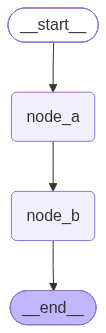

In [24]:
from langgraph.graph import StateGraph, START, END
from typing import TypedDict

class OverAllState(TypedDict):
    username: str
    greeting: str
    output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "greeting": "Dear " + state["username"]
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "output": state["greeting"] + "，你好！"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_edge(START, "node_a")
builder.add_edge("node_a", "node_b")
builder.add_edge("node_b", END)

graph = builder.compile()
res = graph.invoke({"username": "小黄"})
print(res)

from IPython.display import display

display(graph)

{'username': '小黄', 'greeting': 'Dear 小黄', 'output': 'Dear 小黄，你好！'}


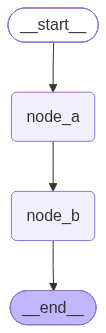

In [26]:

from langgraph.graph import StateGraph, START, END
from typing import TypedDict

class OverAllState(TypedDict):
    username: str
    greeting: str
    output: str

def node_a(state: OverAllState) -> OverAllState:
    return {
        "greeting": "Dear " + state["username"]
    }

def node_b(state: OverAllState) -> OverAllState:
    return {
        "output": state["greeting"] + "，你好！"
    }

builder = StateGraph(state_schema=OverAllState)
builder.add_edge(START, "node_a")
builder.add_sequence([node_a, node_b])
'''相比手动调用多次 add_node 和 add_edge，add_sequence 更适合用于构建简单的线性执行流程'''
builder.add_edge("node_b", END)
"""和 END 不同，START 通常不能省略。因为 START 不只是一个语义上的起点标记，它还用于告诉 LangGraph：图运行时应当从哪些节点开始执行。也就是说，下面这条边是启动图执行的关键："""
graph = builder.compile()
res = graph.invoke({"username": "小黄"})
print(res)

from IPython.display import display

display(graph)

============================== -> poem_res <- ==============================
{'topic': '布偶狗', 'content_type': '诗', 'poem': '《布偶狗》\n绒团乖巧坐门庭，慧眼玲珑似解情。\n莫道无言少机变，伴读陪玩慰此生。\n\n注：我的创作思路是抓住布偶狗作为玩具与伴侣的双重特性。首句“绒团乖巧”写其形态与静态美，次句“慧眼玲珑”拟人化其灵动。后两句转写其陪伴功能，通过“伴读陪玩”的日常场景，展现其慰藉心灵的情感价值。全诗在咏物中寄寓对陪伴者的温情。'}
============================== -> joke_res <- ==============================
{'topic': '布偶狗', 'content_type': '笑话', 'joke': '## 布偶狗的笑话\n\n有一天，一只布偶狗在公园里散步，遇到了一只真的狗。\n\n真狗问：“兄弟，你是什么品种？怎么长得这么精致？”\n\n布偶狗说：“我是布偶狗。”\n\n真狗一脸困惑：“布偶？那不是猫吗？你是猫还是狗？”\n\n布偶狗叹了口气：“我也不知道。我主人买我的时候，说是‘布偶狗’，结果我天天在家喵喵叫。”\n\n真狗：“……那你到底会不会看家？”\n\n布偶狗：“当然会！上次小偷来了，我坐在门口盯着他看，他被我萌得受不了，自己把东西还回去，还顺手把地拖了。”\n\n真狗：“那你吃什么？”\n\n布偶狗：“猫粮。但我假装吃狗粮的时候，会悄悄把颗粒摆成鱼的形状。”\n\n真狗沉默了一会儿，问：“那你……到底该去猫砂盆还是该去外面遛？”\n\n布偶狗眼神空洞地望着远方：“这就是我每天最焦虑的事。每次我想去外面，我主人就抱我去猫砂盆；每次我想用猫砂盆，我主人又给我套上牵引绳。”\n\n真狗同情地拍拍它的肩膀：“兄弟，你这不是布偶狗，你这是薛定谔的宠物——在猫和狗之间量子叠加。”\n\n布偶狗点点头：“所以我现在学会了折中——我蹲在马桶上，一边冲水一边汪汪叫。”\n\n真狗：“……主人没疯？”\n\n布偶狗：“疯了。他现在逢人就说：‘我家狗会自己上厕所，但上完还要照镜子整理毛发。’”'}


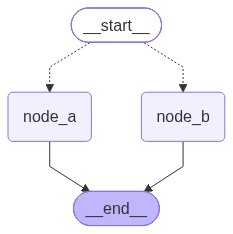

In [27]:
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    content_type: str
    poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")]).content

    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([HumanMessage(f"写一个关于 {state['topic']} 的笑话")]).content

    return {
        "joke": joke
    }

def router(state: OverAllState) -> Literal["node_a", "node_b"]:
    if "诗" in state["content_type"]:
        return "node_a"
    return "node_b"

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_conditional_edges(START, router)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶狗", "content_type": "诗"})
joke_res = graph.invoke({"topic": "布偶狗", "content_type": "笑话"})

print('=' * 30, '-> poem_res <-', '=' * 30)
print(poem_res)
print('=' * 30, '-> joke_res <-', '=' * 30)
print(joke_res)

from IPython.display import display
'''__start__指向node_a和node_b的线是虚线，这表示节点的跳转是有条件的，不是固定的'''
display(graph)

============================== -> poem_res <- ==============================
{'topic': '布偶狗', 'content_type': '诗', 'poem': '《布偶狗》\n绒团静卧似憨熊，慧眼圆睁态自慵。\n莫道无言少机警，忠心长伴乐无穷。\n\n赏析：这首作品以布偶狗为题材，通过“绒团静卧”、“慧眼圆睁”等生动描绘，展现其可爱形象。后两句“莫道无言少机警，忠心长伴乐无穷”，巧妙转折，既赞其机警，更颂其忠心，表达了对布偶狗陪伴的珍视与喜爱，语言凝练，意境温馨。', 'ci_poem': '《鹧鸪天·布偶狗》\n绒团乖巧坐锦茵，琉璃瞳子映灯温。\n尾摇犹带憨态影，耳动偏藏机敏魂。\n左顾右盼，前蹲后立，绕膝翻扑戏红尘。\n纵无血肉身躯软，也胜寒宵孤独人。\n\n注：我的仿写思路是借鉴李清照活泼婉约的笔法，通过“绒团”“琉璃瞳”等意象刻画布偶狗的静态美，再以“尾摇”“耳动”等动态描写赋予其灵性。末句“纵无血肉身躯软，也胜寒宵孤独人”化用李词“怎一个愁字了得”的转折句式，在对比中凸显布偶狗慰藉孤独的深层意蕴。'}
============================== -> joke_res <- ==============================
{'topic': '布偶狗', 'content_type': '笑话', 'ci_poem': '《鹧鸪天·布偶狗》\n绒耳初缝线脚匀，乌珠嵌就愈传神。\n憨眠常伴书窗暖，痴立偏宜雪案新。\n衔素袜，扑纱巾，天生灵性胜真身。\n莫言无吠堪守户，衔取飞花当碎银。\n\n注：我的作品以布偶狗为咏诵对象，通过“绒耳”“乌珠”等细腻刻画其形态，再以“衔素袜”“扑纱巾”等灵动描写赋予其拟人化情趣。结句“衔取飞花当碎银”巧妙化用杨万里“戏掬清泉洒蕉叶，儿童误认雨声来”的童趣，以飞花为银的想象既呼应布偶狗无吠守户的特性，又暗含对纯真世界的向往。', 'joke': '## 布偶狗\n\n小明过生日，妈妈送了他一只布偶狗。\n\n小明很高兴，抱着布偶狗又亲又摸。\n\n爸爸下班回家，看见小明正对着布偶狗说话：“狗狗乖，狗狗听话，狗狗不要乱叫哦。”\n\n爸爸笑了：“傻孩子，那是布偶狗，不是真的狗，不会叫的。”\n\n小明抬起头，一脸认

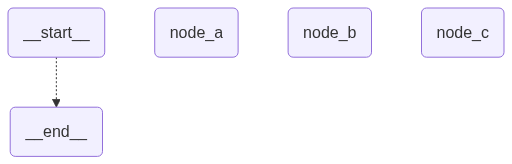

In [28]:
'''如果不希望路由函数直接返回节点名，而是返回业务语义更强的标识，可以使用 **`path_map`** 进行映射。如下：'''
'''
def router(state: OverAllState) -> Literal["a", "b"]:
    if "诗" in state["content_type"]:
        return "a"
    return "b"

builder.add_conditional_edges(
    START,
    router,
    path_map={
        "a": "node_a",
        "b": "node_b",
    }
)
此时返回的 **`"a"`** 和 **`"b"`** 可以不是图中已注册的节点名称，但要通过 **`path_map`** 映射到正确的节点
这种写法的好处是：
- 路由函数可以返回业务含义更清晰的标签；
- 图节点名称可以保持工程化命名；
- 渲染图结构时，边上可以显示路由标签，使图更容易理解。
'''



'''在这个例子中：
- 当 **`content_type`** 包含 **`"诗"`** 时，同时触发 **`node_a`** 和 **`node_c`**；
- 否则同时触发 **`node_b`** 和 **`node_c`**。router函数返回的是序列而非单个节点，渲染器无法推断节点间的映射关系。

通过 **`path_map`** 可以显示声明映射关系，明确下游节点集合，在提升代码可读性的同时，也有助于渲染器正确展示条件边。
当前场景下 **`path`** 返回值中的字符串就是合法的节点名称，**`path_map`** 可以是字典
'''
from collections.abc import Sequence
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)

class OverAllState(TypedDict):
    topic: str
    content_type: str
    poem: str
    ci_poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")]).content

    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([HumanMessage(f"写一个关于 {state['topic']} 的笑话")]).content

    return {
        "joke": joke
    }

def node_c(state: OverAllState) -> OverAllState:
    ci_poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的词")]).content

    return {
        "ci_poem": ci_poem
    }

def router(state: OverAllState) -> Sequence[Literal["node_a", "node_b", "node_c"]]:
    if "诗" in state["content_type"]:
        return ["node_a", "node_c"]
    return ["node_b", "node_c"]

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_conditional_edges(
    START,
    router
)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶狗", "content_type": "诗"})
joke_res = graph.invoke({"topic": "布偶狗", "content_type": "笑话"})

print('=' * 30, '-> poem_res <-', '=' * 30)
print(poem_res)
print('=' * 30, '-> joke_res <-', '=' * 30)
print(joke_res)

from IPython.display import display

display(graph)

============================== -> poem_res <- ==============================
{'topic': '布偶狗', 'content_type': '诗', 'poem': '《布偶狗》\n绒团乖巧卧窗台，日日凝神待主来。\n忽见门开摇尾扑，却原风动影徘徊。\n\n注：我的创作思路是抓住布偶狗“静待”与“误认”的瞬间，通过“绒团”、“凝神”、“摇尾扑”等具象描写，展现其忠诚可爱的特性。尾句“风动影徘徊”的错觉，既呼应首句的“待主来”，又暗含淡淡怅惘，使小诗在童趣之外多了一层余韵。', 'ci_poem': '《鹧鸪天·布偶狗》\n绒团乖巧拟形真，玲珑憨态解语频。\n轻拥似抱一团云，软语轻吟慰客魂。\n身虽假，意犹温，伴人朝夕胜真真。\n不须骨肉不须魂，只予温馨不染尘。\n\n赏析：这首作品以布偶狗为题材，通过“绒团乖巧”、“玲珑憨态”等生动描绘，展现其可爱形象。下片以“身虽假，意犹温”转折，强调其虽无生命却能给予温暖陪伴，胜似真实。尾句“只予温馨不染尘”巧妙双关，既指布偶洁净，又喻其带来的纯粹慰藉，表达了对布偶狗陪伴价值的深情赞美。'}
============================== -> joke_res <- ==============================
{'topic': '布偶狗', 'content_type': '笑话', 'ci_poem': '《鹧鸪天·布偶狗》\n绒尾摇风软耳垂，琉璃珠嵌眼波微。\n线牵灵魄随人转，棉裹憨躯伴影移。\n衔锦袜，扑帘帷，绕膝昂首献欢时。\n莫嫌腹内空空也，胜却人间薄幸儿。\n\n注：我的创作思路是借布偶狗之形，讽喻世情。上片以“绒尾”“琉璃珠”等意象勾画布偶狗精巧外观，暗藏提线操控之悲。下片通过衔袜扑帘等拟态动作，反讽其虽无真心却强作欢颜。结句“胜却人间薄幸儿”乃点睛之笔，以物喻人，直指人心易变，反不如傀儡忠诚，形成强烈反讽。', 'joke': '有一天，一只布偶狗被主人带去了宠物店。\n\n店员问：“您好，请问这只狗是什么品种？”\n\n主人骄傲地说：“这是布偶狗。”\n\n店员愣住了：“布偶……不是猫吗？”\n\n主人摇摇头，摸了摸布偶狗的脑袋：“不，它是狗。你看，它会汪汪叫。”\n\n说完主人捏了捏布偶狗，布偶

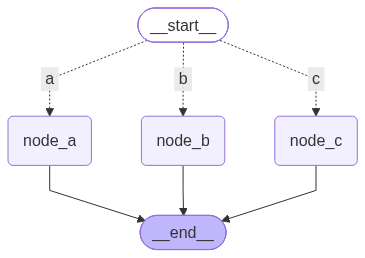

In [36]:
from collections.abc import Sequence
from typing import TypedDict, Literal
from langgraph.graph import StateGraph, START, END
from langchain.messages import HumanMessage
from langchain_deepseek import ChatDeepSeek

from dotenv import load_dotenv

load_dotenv(override=True)

model = ChatDeepSeek(
    model="deepseek-v4-flash",
    extra_body={
        "thinking": {
            "type": "disabled"
        }
    }
)


class OverAllState(TypedDict):
    topic: str
    content_type: str
    poem: str
    ci_poem: str
    joke: str

def node_a(state: OverAllState) -> OverAllState:
    poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的七言绝句")]).content

    return {
        "poem": poem
    }

def node_b(state: OverAllState) -> OverAllState:
    joke = model.invoke([HumanMessage(f"写一个关于 {state['topic']} 的笑话")]).content

    return {
        "joke": joke
    }

def node_c(state: OverAllState) -> OverAllState:
    ci_poem = model.invoke([HumanMessage(f"写一首关于 {state['topic']} 的词")]).content

    return {
        "ci_poem": ci_poem
    }

def router(state: OverAllState) -> Sequence[Literal["node_a", "node_b", "node_c"]]:
    if "诗" in state["content_type"]:
        return ["a", "c"]
    return ["b", "c"]

builder = StateGraph(state_schema=OverAllState)
builder.add_node("node_a", node_a)
builder.add_node("node_b", node_b)
builder.add_node("node_c", node_c)
builder.add_conditional_edges(
    START,
    router,
    path_map={
        "a": "node_a",
        "b": "node_b",
        "c": "node_c",
    }
)
builder.add_edge("node_a", END)
builder.add_edge("node_b", END)
builder.add_edge("node_c", END)

graph = builder.compile()
poem_res = graph.invoke({"topic": "布偶狗", "content_type": "诗"})
joke_res = graph.invoke({"topic": "布偶狗", "content_type": "笑话"})

print('=' * 30, '-> poem_res <-', '=' * 30)
print(poem_res)
print('=' * 30, '-> joke_res <-', '=' * 30)
print(joke_res)

from IPython.display import display

display(graph)